<div style='background-color:#EEF4F7; border-left:4px solid #6F8996; border-radius:6px; padding:14px 18px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">Homework 10 - The Second Half of CRISP-DM</h1>
<p style="color:#243038; margin:0.4em 0;"><strong>LTAT.02.002 Introduction to Data Science - Autumn 2026</strong></p>
<p style="color:#243038; margin:0.4em 0;"><strong>Deadline: November 30th, 2026 at noon (12:00 Europe/Tallinn time)</strong></p>

</div>

Note! This homework is submitted as groups. One group member submits on behalf of the whole team.

Not every question fits every project. If a question does not apply to yours, first adapt it to your project, and then answer it.

Most questions have an empty code cell above the answer box. Use it if code, a table or a plot helps your answer, and leave it empty if it does not - for most questions a written answer on its own is enough. Where a question asks you to show the data or a graph, use the cell.

In the previous project homework (HW7) you worked out what your project is about and what is in your data. This one takes you through the rest of CRISP-DM: preparing the data, applying a method, judging the result, and getting it ready for other people to see.

**Your project does not have to be finished by the deadline of this homework.** It has to be finished by the poster deadline, one week later. The point of the questions below is to guide and help you finish your project on time.

Where this homework sits in the process:

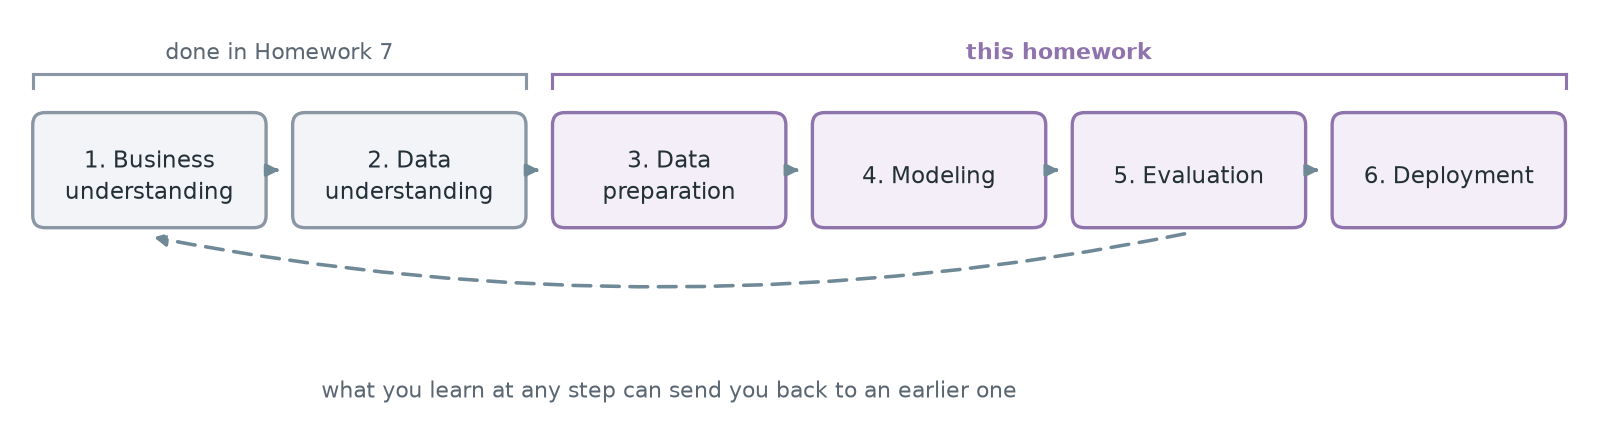

**Your project**

State these again, so that this notebook can be read on its own.

**Group ID and topic:** <span style="color:#B3261E;">I8 - Forecast Fusion</span>

**Team members:** <span style="color:#B3261E;">Marken Nisu & Pert Koduvere</span>

**Repository URL:** <span style="color:#B3261E;">https://github.com/MarkenNisu/Machine_Learning_For_Weather</span>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import ParameterGrid, GridSearchCV, PredefinedSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">1. Data preparation (0.5 points)</h1>

</div>

This is **step 3** of CRISP-DM. The aim is to get from the raw data to a table you can actually work with, and to be able to say exactly what you changed and why. Someone reading your repository later should be able to repeat every one of those steps.

**a. Show the prepared data.**

Show the table your analysis runs on - the one you ended up with after cleaning, not the raw file you started from. Print its shape, the column names and the first few rows.

The rest of this task asks how you got from the raw data to this, so it helps to have it in front of you first.

In [2]:
# TODO (if applicable)
df = pd.read_csv("../data/processed/weather_dataset_2024_2026.csv", parse_dates=["time"])

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())

display(df.head())

Shape: (6624, 13)

Columns: ['time', 'actual_temperature', 'actual_precipitation', 'actual_wind_speed', 'temperature_ECMWF', 'temperature_GFS', 'temperature_ICON_EU', 'precipitation_ECMWF', 'precipitation_GFS', 'precipitation_ICON_EU', 'wind_speed_ECMWF', 'wind_speed_GFS', 'wind_speed_ICON_EU']


,time,actual_temperature,actual_precipitation,actual_wind_speed,temperature_ECMWF,temperature_GFS,temperature_ICON_EU,precipitation_ECMWF,precipitation_GFS,precipitation_ICON_EU,wind_speed_ECMWF,wind_speed_GFS,wind_speed_ICON_EU
0,2024-06-01 00:00:00,17.4,0.0,0.8,17.2,15.5,17.4,0.0,1.0,0.0,1.90,2.66,1.04
1,2024-06-01 01:00:00,17.1,0.0,1.2,16.4,15.6,16.5,0.0,0.0,0.0,1.30,2.19,1.13
2,2024-06-01 02:00:00,15.3,0.0,1.3,16.0,15.5,16.0,0.0,0.0,0.0,0.90,1.71,1.08
3,2024-06-01 03:00:00,14.5,0.0,0.7,16.2,15.1,15.6,0.3,0.0,0.0,1.03,2.18,1.00
4,2024-06-01 04:00:00,14.5,0.0,0.9,16.8,15.0,15.3,0.3,0.0,0.0,1.63,2.48,0.61


<span style="color:#B3261E;"><strong>Answer:</strong></span> The final prepared dataset contains 6,624 hourly observations and 13 columns, covering the summer months (June–August) of 2024, 2025, and 2026 in the Tartu-Tõravere region.

The dataset combines actual weather measurements from the Tartu-Tõravere weather station with 24-hour-ahead forecasts from ECMWF, GFS, and ICON-EU. It includes temperature, precipitation, and wind speed measurements and forecasts.

**b. What did you have to fix in the data?**

**Now go back to where you started.** List the problems you found - missing values, duplicates, impossible or inconsistent values, wrong data types - and say what you did with each one and why.

In [3]:
# TODO (if applicable)
print("Missing values:", df.isna().sum().sum())
print("Duplicate timestamps:", df["time"].duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nNegative precipitation values:")
print((df.filter(like="precipitation") < 0).sum())

print("\nNegative wind speed values:")
print((df.filter(like="wind_speed") < 0).sum())

Missing values: 0
Duplicate timestamps: 0

Data types:
time                     datetime64[us]
actual_temperature              float64
actual_precipitation            float64
actual_wind_speed               float64
temperature_ECMWF               float64
temperature_GFS                 float64
temperature_ICON_EU             float64
precipitation_ECMWF             float64
precipitation_GFS               float64
precipitation_ICON_EU           float64
wind_speed_ECMWF                float64
wind_speed_GFS                  float64
wind_speed_ICON_EU              float64
dtype: object

Negative precipitation values:
actual_precipitation     0
precipitation_ECMWF      0
precipitation_GFS        0
precipitation_ICON_EU    0
dtype: int64

Negative wind speed values:
actual_wind_speed     0
wind_speed_ECMWF      0
wind_speed_GFS        0
wind_speed_ICON_EU    0
dtype: int64


<span style="color:#B3261E;"><strong>Answer:</strong></span> The raw weather station data and forecast data required preprocessing before analysis.

The observation files used semicolon separators and comma decimal notation, which had to be handled correctly. Timestamps were standardized to the Europe/Tallinn time zone to align actual measurements with forecasts.

The data was filtered to include only June, July, and August from 2024 to 2026. Forecasts from the three weather models were reorganized and merged with actual observations using matching hourly timestamps.

The final dataset was checked for missing values, duplicate timestamps, and data types. It contains no missing values or duplicate timestamps.

**c. What does one row represent now, and what goes into the analysis?**

Name the columns you kept, any new columns you built from the existing ones, and the columns you left out.

In [4]:
# TODO (if applicable)

<span style="color:#B3261E;"><strong>Answer:</strong></span> Each row represents one hour of weather data from the Tartu-Tõravere region.

The dataset contains a timestamp, three actual weather measurements (temperature, precipitation, and wind speed), and nine forecast features from ECMWF, GFS, and ICON-EU.

For temperature and wind speed prediction, the three corresponding model forecasts were used as input features, while the actual measured value was used as the target.

For precipitation classification, a binary target was created from the actual precipitation values: 0 for no precipitation and 1 for precipitation greater than 0 mm.

The timestamp was used for chronological splitting. Data outside the selected summer months and unnecessary source columns were excluded. No additional weather predictors were created for the final models.

**d. How did you split the data, and why that way?**

Randomly, by time, or by group? Then name one thing in your data that could **leak** the answer into the inputs, and say how you avoided it. A leak is information that would not be available at the moment the prediction is made - for example a column that is only filled in after the outcome is already known.

If your project does not predict anything, answer instead how you made sure your conclusions are not driven by one unusual part of the data.

In [5]:
# TODO (if applicable)

<span style="color:#B3261E;"><strong>Answer:</strong></span> The dataset was split chronologically rather than randomly because weather observations form a time series.

Data from 2024 was used for training, 2025 for validation and model selection, and 2026 for independent testing. After selecting the best models and hyperparameters, the final models were retrained using data from both 2024 and 2025.

This approach reduces the risk of data leakage between training and testing.

For example, actual temperature, precipitation, and wind speed measurements were used only as target values, not as input features. The machine learning models used forecasts from ECMWF, GFS, and ICON-EU that were generated before the corresponding observations.

For Logistic Regression, StandardScaler was fitted on the training data within a pipeline, preventing information from the validation or test data from influencing the scaling process.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 1 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 1<br>
<strong>Time spent (voluntary):</strong> 1 hours<br>
<strong>Questions and comments (voluntary):</strong> </p>

</div>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">2. Modeling (0.5 points)</h1>

</div>

This is **step 4**. The point is not to reach the best possible result - it is to have something that works from end to end, and something simple to compare it against.

**a. Start with a baseline.**

Your baseline is the simplest thing that is not your method. For a prediction task that is the majority class, the mean, or an obvious rule. For a clustering or descriptive task it is the picture you would get without the method - everything in one group, or the overall average with no breakdown. Report what it gives you.

In [6]:
# TODO (if applicable)
def baseline_predict_temperature(current_temperature):
    return current_temperature

<span style="color:#B3261E;"><strong>Answer:</strong></span> The nature of our problem requires creating multiple machine learning models, one for predicting each feature - temperature, wind speed, precipitation. This task is completed based on one of those, predicting temperature. The baseline model predicts the temperature 24 hours from now to be equal to the current temperature.

**b. Now your actual method.**

Which method did you use, and why is it a reasonable choice for your kind of problem - classification, regression, clustering, or description?

In [7]:

df["hour_of_day"] = df["time"].dt.hour
df["hour_sin"] = np.sin(2 * np.pi * df["hour_of_day"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour_of_day"] / 24)

df["time"] = pd.to_datetime(df["time"])
df = df.sort_values("time").set_index("time")
df["temp_at_prediction"] = df["actual_temperature"].shift(freq="24h").reindex(df.index)

df = df.reset_index()

train = df[df["time"].dt.year == 2024]
val = df[df["time"].dt.year == 2025]
test = df[df["time"].dt.year == 2026]

features = [
    "temperature_ECMWF",
    "temperature_GFS",
    "temperature_ICON_EU",
    "hour_sin",
    "hour_cos",
]

target = "actual_temperature"

X_train = train[features]
y_train = train[target]

X_val = val[features]
y_val = val[target]

X_test = test[features]
y_test = test[target]

In [8]:
X_all = pd.concat([X_train, X_val])
y_all = pd.concat([y_train, y_val])
split = PredefinedSplit(np.r_[np.full(len(X_train), -1), np.zeros(len(X_val))])

param_grid = {
    "n_estimators":     [250, 500, 1000],
    "max_depth":        [3, 5, 8, 12, None],
    "min_samples_leaf": [5, 10, 20, 50],
    "max_features":     [0.33, 0.5, 1.0],
}

search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid,    cv=split,
    scoring="neg_root_mean_squared_error",
    refit=False,
    n_jobs=1,
    verbose=1,
)

search.fit(X_all, y_all)

print("best params:", search.best_params_)
print("best val RMSE:", -search.best_score_)

Fitting 1 folds for each of 180 candidates, totalling 180 fits
best params: {'max_depth': 8, 'max_features': 1.0, 'min_samples_leaf': 10, 'n_estimators': 250}
best val RMSE: 1.2845959722560765


<span style="color:#B3261E;"><strong>Answer:</strong></span> The method used is random forest. This fits the problem, because it can find patterns which linear regression struggles with. For example, it could find patterns like this: when predictions of forecasts A and B differ by more than 2.5 °C then trust forecast C. 

**c. How do you measure success?**

Name the measure you report and say why it fits your goal. (For example accuracy, precision, recall, F1 or ROC AUC for classification, RMSE or MAE for regression - or something else that suits your project.)

<span style="color:#B3261E;"><strong>Answer:</strong></span> Success is measured using RMSE due to temperature being a continuous attribute. RMSE was chosen specifically over MAE, because it punishes larger errors which are more important for this task. An error of 1 °C is not as problematic as predictions being off by 5 °C or 10 °C.

**d. What did you try, and how did you choose?**

Different settings, different parameters, several methods - say what you compared and on what basis you picked one.

<span style="color:#B3261E;"><strong>Answer:</strong></span> Model parameters were chosen using a parameter grid, where a grid search is done on the given parameters. The algorithm chose the parameters that produced the lowest RMSE.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 2 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 1<br>
<strong>Time spent (voluntary):</strong> 1 hours<br>
<strong>Questions and comments (voluntary):</strong> </p>

</div>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">3. Evaluation (0.5 points)</h1>

</div>

This is **step 5**. Steps 4 and 5 are easy to confuse. Step 4 asks whether the method ran; step 5 asks whether the result is any good, and whether it answers the question you started from.

**a. Put the numbers side by side.**

Your baseline and your method, measured on data the method did not learn from. A small table or a plot is enough.

In [10]:
t = test.dropna(subset=["actual_temperature", "temp_at_prediction"])

rmse_baseline_model = root_mean_squared_error(
    t["actual_temperature"],
    baseline_predict_temperature(t["temp_at_prediction"]),
)

rf = RandomForestRegressor(random_state=42, n_jobs=-1, **search.best_params_)
rf.fit(X_all, y_all)  

rf_pred = rf.predict(X_test)

rmse_random_forest = root_mean_squared_error(y_test, rf_pred)

print(rmse_random_forest)
print(rmse_baseline_model)


1.1398090624587705
2.8270564494714585


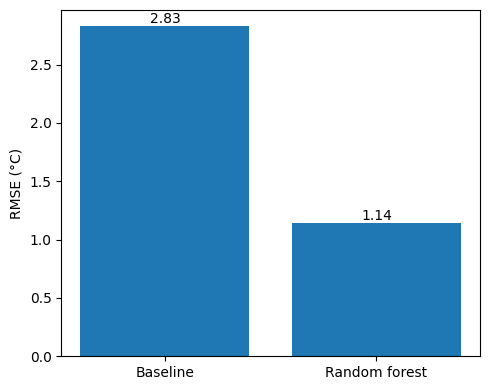

In [10]:

plt.figure(figsize=(5, 4))
bars = plt.bar(["Baseline", "Random forest"],
               [rmse_baseline_model, rmse_random_forest])
plt.bar_label(bars, fmt="%.2f")
plt.ylabel("RMSE (°C)")
plt.tight_layout()
plt.show()

<span style="color:#B3261E;"><strong>Answer:</strong></span> A significant improvement from approximately 2.8 °C by the baseline model and more than two times less for random forest - approximately 1.1 °C

**b. What does your result actually mean for someone who would use it?**

A number on its own - "accuracy 0.87" - does not tell anyone whether the work was worth doing. Say what someone could now do that they could not do before, and whether your result is good enough for them to rely on.

<span style="color:#B3261E;"><strong>Answer:</strong></span> This means that using weather forecast data and combining them gives a better results for comparing temperatures than a simple assumption that temperature in 24 hours is the same it is now. In the latter case you will be off by almost 3 °C on average while forecasts predict within 1.14 of the real temperature on average.

**c. What is the biggest threat to your conclusion?**

Too little data, a leak, a sample that does not represent what you claim, a measure that flatters your method - name the one that worries you most, and say how much it worries you.

<span style="color:#B3261E;"><strong>Answer:</strong></span> The models are trained based on summer data only and only for Tõravere weather station. This means that results can be interpreted for summer data only in Tõravere region. The results can not be generalized because this could have been an unlucky location choice for the models, perhaps they are terrible in Tartumaa. Or the opposite, for some reason they are very good in the chosen reason. The same logic applies to seasons of the year.

**d. Did anything send you back to an earlier step?**

Look at the diagram at the top of this notebook. If something you found here made you change the data preparation, the method, or even the question itself, say which step you went back to and what you changed. If nothing did, say that.

<span style="color:#B3261E;"><strong>Answer:</strong></span> Nothing specific sent us back.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 3 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 1<br>
<strong>Time spent (voluntary):</strong> 1 hours<br>
<strong>Questions and comments (voluntary):</strong> </p>

</div>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">4. Towards the poster (0.5 points)</h1>

</div>

This is **step 6**, deployment. In a company this is where the result is put to use; on this course your poster and your repository are how your work reaches other people.

**These do not have to be the figures that end up on your poster.** You still have a week to make those. The point here is to work out *now* what in your project can actually be shown as a graph, and to have a first version in front of you that you can improve if needed.

**a. Two or three graphs from your project.**

Label the axes on each one. Then, in the answer below, write one sentence per graph saying what a reader should take from it.

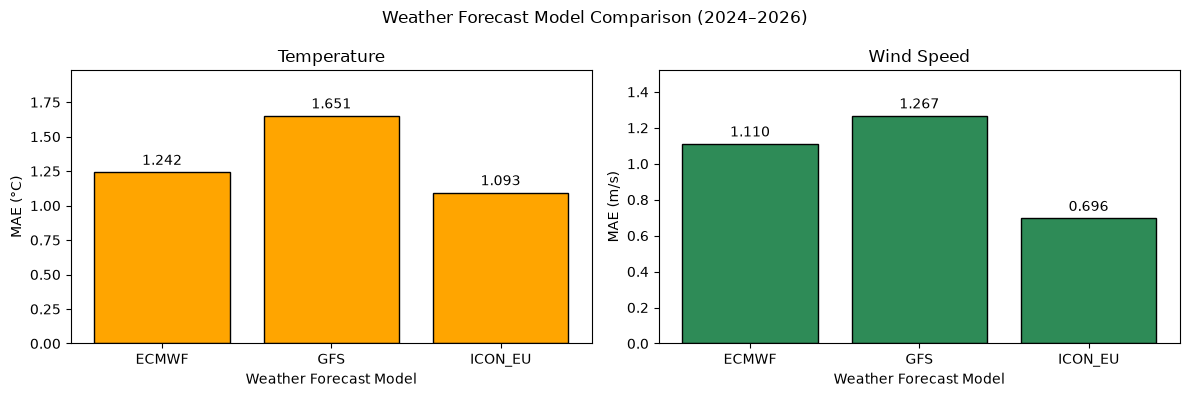

In [14]:
# TODO: first graph
models = ["ECMWF", "GFS", "ICON_EU"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, feature, unit, color in [
    (axes[0], "temperature", "°C", "orange"),
    (axes[1], "wind_speed", "m/s", "seagreen")
]:
    errors = [
        mean_absolute_error(
            df[f"actual_{feature}"],
            df[f"{feature}_{model}"]
        )
        for model in models
    ]

    bars = ax.bar(
        models,
        errors,
        color=color,
        edgecolor="black"
    )

    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("Weather Forecast Model")
    ax.set_ylabel(f"MAE ({unit})")
    ax.set_ylim(0, max(errors) * 1.2)

plt.suptitle("Weather Forecast Model Comparison (2024–2026)")
plt.tight_layout()
plt.show()

In [15]:
# For the second and third graph
# Load data
df = pd.read_csv(
    "../data/processed/weather_dataset_2024_2026.csv",
    parse_dates=["time"]
)

# Split data
train_final = df[df["time"].dt.year.isin([2024, 2025])]
test_final = df[df["time"].dt.year == 2026]

# Temperature
temp_features = [
    "temperature_ECMWF",
    "temperature_GFS",
    "temperature_ICON_EU"
]

temp_lr = LinearRegression()

temp_lr.fit(
    train_final[temp_features],
    train_final["actual_temperature"]
)

temp_pred_2026 = temp_lr.predict(test_final[temp_features])

# Wind speed
wind_features = [
    "wind_speed_ECMWF",
    "wind_speed_GFS",
    "wind_speed_ICON_EU"
]

wind_lr = LinearRegression()

wind_lr.fit(
    train_final[wind_features],
    train_final["actual_wind_speed"]
)

wind_pred_2026 = wind_lr.predict(test_final[wind_features])

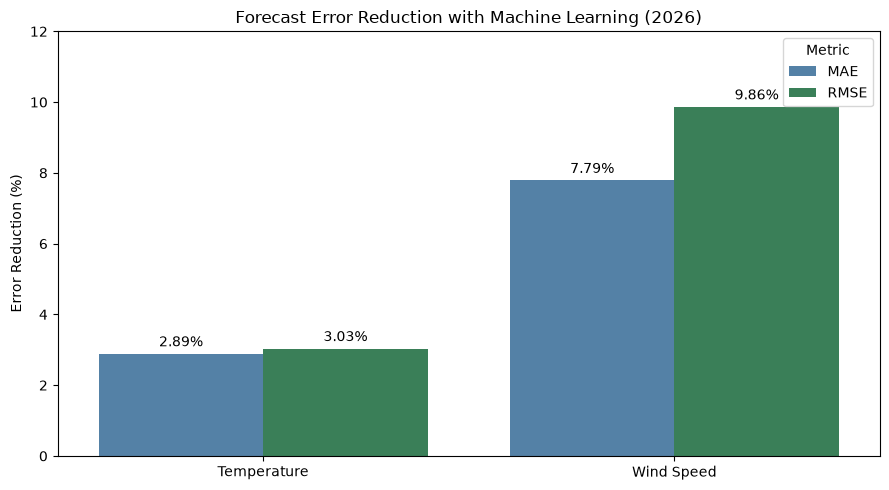

In [16]:
# TODO: second graph
results = []

for feature, actual, icon, ml in [
    ("Temperature", test_final["actual_temperature"],
     test_final["temperature_ICON_EU"], temp_pred_2026),

    ("Wind Speed", test_final["actual_wind_speed"],
     test_final["wind_speed_ICON_EU"], wind_pred_2026)
]:
    for metric, function in [
        ("MAE", mean_absolute_error),
        ("RMSE", root_mean_squared_error)
    ]:
        icon_error = function(actual, icon)
        ml_error = function(actual, ml)

        results.append({
            "Feature": feature,
            "Metric": metric,
            "Improvement (%)": (icon_error - ml_error) / icon_error * 100
        })

improvement_df = pd.DataFrame(results)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=improvement_df,
    x="Feature",
    y="Improvement (%)",
    hue="Metric",
    palette=["steelblue", "seagreen"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Forecast Error Reduction with Machine Learning (2026)")
plt.xlabel("")
plt.ylabel("Error Reduction (%)")
plt.ylim(0, 12)
plt.legend(title="Metric")

plt.tight_layout()
plt.show()

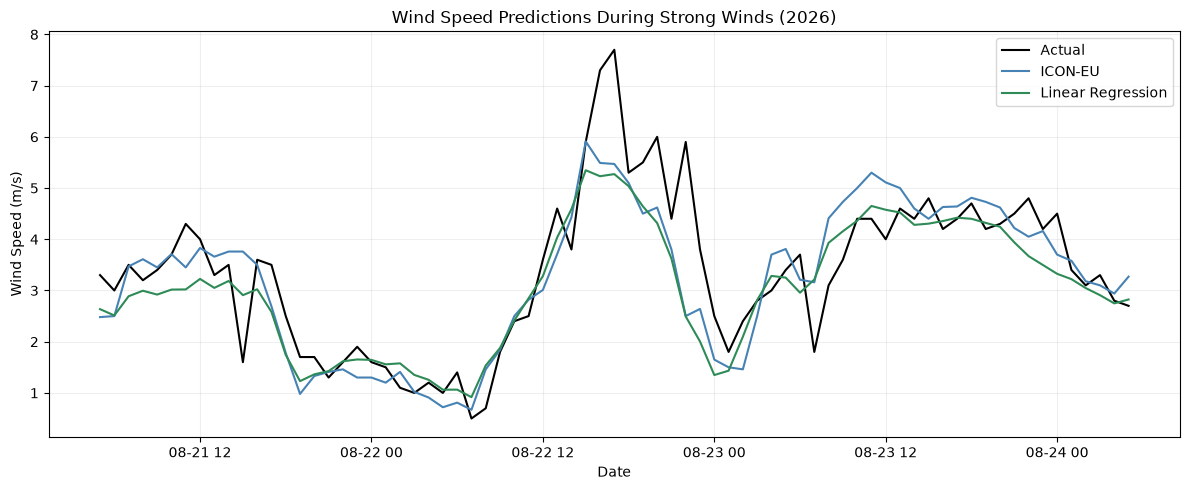

In [17]:
# TODO: third graph, if you have one
wind_plot = pd.DataFrame({
    "time": test_final["time"].values,
    "Actual": test_final["actual_wind_speed"].values,
    "ICON-EU": test_final["wind_speed_ICON_EU"].values,
    "Linear Regression": wind_pred_2026
})

# Find the hour with the strongest observed wind
peak_time = wind_plot.loc[
    wind_plot["Actual"].idxmax(), "time"
]

# Select 36 hours before and after the peak
wind_period = wind_plot[
    (wind_plot["time"] >= peak_time - pd.Timedelta(hours=36)) &
    (wind_plot["time"] <= peak_time + pd.Timedelta(hours=36))
]

plt.figure(figsize=(12, 5))

plt.plot(wind_period["time"], wind_period["Actual"],
         label="Actual", color="black")

plt.plot(wind_period["time"], wind_period["ICON-EU"],
         label="ICON-EU", color="steelblue")

plt.plot(wind_period["time"], wind_period["Linear Regression"],
         label="Linear Regression", color="seagreen")

plt.title("Wind Speed Predictions During Strong Winds (2026)")
plt.xlabel("Date")
plt.ylabel("Wind Speed (m/s)")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

<span style="color:#B3261E;"><strong>Answer:</strong></span>  
Weather Forecast Model Comparison: ICON-EU achieved the lowest temperature and wind speed prediction errors among the three original weather forecasting models during the summers of 2024–2026.

Forecast Error Reduction with Machine Learning: Linear Regression reduced temperature MAE by 2.89% and wind speed MAE by 7.79% compared to ICON-EU on the independent 2026 test dataset.

Wind Speed Predictions During Strong Winds: Both ICON-EU and Linear Regression underestimated the strongest observed wind speeds, demonstrating that improved overall accuracy does not necessarily mean better predictions during extreme weather conditions.

**b. The front page of your repository.**

Write the README: the project name and the authors, the motivation and the goal, what is in which file, and how someone else would repeat your analysis. Paste it here as well.

<span style="color:#B3261E;"><strong>Answer:</strong></span>
# Forecast Fusion

**Authors:** Marken Nisu, Pert Koduvere

## Project Overview

This project investigates the accuracy of weather forecasts in the Tartu-Tõravere region of Estonia during the summers of 2024–2026.

We compare three weather forecasting models: ECMWF, GFS, and ICON-EU. We also investigate whether machine learning can improve forecasting accuracy by combining predictions from these models.

## Research Questions

1. Which weather forecasting model provides the most accurate predictions for temperature, precipitation, and wind speed?
2. Can machine learning improve forecasting accuracy by combining predictions from ECMWF, GFS, and ICON-EU?

## Dataset

The dataset combines actual weather observations from the Estonian Environment Agency's Tartu-Tõravere weather station with historical 24-hour-ahead forecasts from the Open-Meteo Previous Runs API.

- **Period:** June–August, 2024–2026
- **Location:** Tartu-Tõravere, Estonia
- **Observations:** 6,624 hourly records
- **Columns:** 13
- **Variables:** Temperature (°C), precipitation (mm/h), and wind speed (m/s)

The prepared dataset is located at `data/processed/weather_dataset_2024_2026.csv`.

## Project Structure

- `01_eda.ipynb` – Exploratory data analysis and visualizations.
- `02_forecast_evaluation.ipynb` – Evaluation and comparison of the original forecasting models.
- `03_machine_learning.ipynb` – Machine learning models, training, evaluation, and visualizations.
- `ML_testing.ipynb` – Additional machine learning experiments, model comparisons, hyperparameter tuning, and previously created visualizations, including prediction plots, error comparisons, and confusion matrices.
- `data/processed/` – Prepared weather dataset used for analysis.

## Methods

For temperature and wind speed prediction, we tested Linear Regression and Random Forest Regressor.

For precipitation occurrence, we tested Logistic Regression and Random Forest Classifier.

The dataset was split chronologically:

- **2024:** Training
- **2025:** Validation and model selection
- **2026:** Independent testing

After model selection, the final models were retrained using data from both 2024 and 2025.

We used MAE and RMSE to evaluate temperature and wind speed predictions, and precision, recall, accuracy, and F1-score for precipitation classification.

## Main Results

ICON-EU was the most accurate original forecasting model according to our primary evaluation metrics.

On the independent 2026 test dataset, Linear Regression reduced temperature MAE by 2.89% and wind speed MAE by 7.79% compared to ICON-EU.

For precipitation occurrence, Logistic Regression achieved an F1-score of 0.5319, compared to 0.5314 for ICON-EU. The difference was negligible.

Overall, machine learning improved temperature and wind speed prediction accuracy, while precipitation classification showed no meaningful improvement in F1-score.

## How to Reproduce the Analysis

1. Clone or download the repository.
2. Install Python and Jupyter Notebook.
3. Install the required libraries:

   `pip install pandas numpy matplotlib seaborn scikit-learn`

4. Ensure the prepared dataset is available in `data/processed/`.
5. Open Jupyter Notebook and run the following notebooks:
   - `01_eda.ipynb` – Exploratory data analysis.
   - `02_forecast_evaluation.ipynb` – Weather forecast model comparison.
   - `03_machine_learning.ipynb` – Machine learning models and final evaluation.
   - `ML_testing.ipynb` – Additional machine learning experiments, model comparisons, hyperparameter tuning, and visualizations.
6. All four notebooks should be executed to reproduce the complete analysis. The `03_machine_learning.ipynb` and `ML_testing.ipynb` notebooks can be run in either order, as they are independent of each other.
7. Adjust the dataset paths if necessary depending on the Jupyter working directory.

## Data Sources

- Estonian Environment Agency – Tartu-Tõravere weather station observations.
- Open-Meteo Previous Runs API – Historical forecasts from ECMWF, GFS, and ICON-EU.

**c. The last week.**

What is left to do, who does it, and by when? The poster PDF, the project information form, the teamwork description form and access to your code repository are all due on Monday 7 December at 12:00.

<span style="color:#B3261E;"><strong>Answer:</strong></span> The main data analysis, forecast evaluation, and machine learning experiments have been completed.

The remaining tasks are:
- **By November 28:** Prepare the first version of the poster – Both members.
- **By December 2:** Review and improve the poster together and finalize the poster PDF – Both members.
- **By December 2:** Complete the project information and teamwork description forms – Both members.
- **By December 6:** Submit all required materials and ensure that the code repository is accessible – Both members.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 4 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 1<br>
<strong>Time spent (voluntary):</strong> 1 hours<br>
<strong>Questions and comments (voluntary):</strong></p>

</div>

<div style='background-color:#FFF6DF; border-top:1px solid #E5CB91; border-left:4px solid #C7952D; border-radius:6px; padding:14px 18px; margin-top:26px; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Final check</h2>
<p style="color:#243038; margin:0.5em 0;">Before submitting, save and choose <strong>Kernel &gt; Restart &amp; Run All</strong>. Fix unexpected errors and check that all written answers remain visible.</p>

</div>

<div style='background-color:#FFF6DF; border-top:1px solid #E5CB91; border-left:4px solid #C7952D; border-radius:6px; padding:14px 18px; margin-top:26px; color:#243038;'>

<p style="color:#243038; margin:0.4em 0;">Thank you for your effort!</p>

</div>